# SOCIAL MEDIA IMPACT ON STUDENTS' LIVES

## **GLOBAL STYLE CONFIGURATION**


This part of the code imports all the necessary libraries for data analysis and visualization, such as **NumPy**, **Pandas**, **Matplotlib** and **Seaborn**. It also imports KaggleHub to access datasets from Kaggle.

Then, it sets the language of the charts to English and defines a consistent *color palette*, assigning specific colors to the different clusters. It also defines the names of the clusters, such as Balanced and Intensive.

Next, it configures the fonts and the general appearance of the charts, including the background, titles, labels, axes, gridlines and legends.

Finally, it defines the labels used for the dataset features and creates a function to save the charts in PNG and SVG formats with high resolution.

In [1]:
# 1. STILE GLOBALE (palette e font del deck)
import os, textwrap
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager as fm
import kagglehub
import pandas as pd

LANG = "en"   # "it" oppure "en": cambia la lingua di titoli ed etichette
def t(it, en): return it if LANG == "it" else en

# --- Palette presa dal PowerPoint ---
BG, INK, NAVY, MUTED = "#FFF9E8", "#1E293B", "#002060", "#64748B"
BLUE, PINK, GREEN, ROSE, SLATE = "#1D6FF2", "#E1306C", "#16A34A", "#FB7185", "#94A3B8"
GRID = "#E7E3D3"

CLUSTER_COLORS = {0: BLUE, 1: PINK, 2: GREEN, 3: NAVY}
CAT_COLORS = [BLUE, PINK, GREEN, NAVY, SLATE, ROSE]

# Nomi dei cluster: modificali con quelli che hai scelto
CLUSTER_NAMES = {0: t("Equilibrati", "Balanced"), 1: t("Moderate", "Intensive")}
def cname(c, full=False):
    n = CLUSTER_NAMES.get(c, f"Cluster {c}")
    return f"Cluster {c} · {n}" if full and c in CLUSTER_NAMES else n

# --- Font: Georgia per i titoli, Calibri per il resto (con alternative se non installati) ---
_avail = {f.name for f in fm.fontManager.ttflist}
def _pick(*names, default): return next((n for n in names if n in _avail), default)
SANS  = _pick("Calibri", "Carlito", "Arial", "Liberation Sans", default="DejaVu Sans")
SERIF = _pick("Georgia", "Gelasio", "Noto Serif", default="DejaVu Serif")

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300,
    "figure.facecolor": BG, "axes.facecolor": BG,
    "font.family": SANS, "font.size": 13,
    "axes.labelsize": 13, "axes.labelcolor": INK,
    "axes.edgecolor": SLATE, "axes.linewidth": 1,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.9,
    "axes.axisbelow": True,
    "xtick.color": INK, "ytick.color": INK,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.frameon": False, "legend.fontsize": 12,
    "svg.fonttype": "none",
})

LABELS = {
    "Daily_Usage_Hours":        t("Ore di uso al giorno", "Daily usage hours"),
    "Weekend_Extra_Hours":      t("Ore extra nel weekend", "Weekend extra hours"),
    "Late_Night_Usage":         t("Uso notturno", "Late-night usage"),
    "Late_Night_Num":           t("Uso notturno", "Late-night usage"),
    "Sleep_Duration_Hours":     t("Ore di sonno", "Sleep duration"),
    "Sleep_Quality_Score":      t("Qualità del sonno", "Sleep quality"),
    "Perceived_Stress_Score":   t("Stress percepito", "Perceived stress"),
    "Mental_Health_Index":      t("Salute mentale", "Mental health index"),
    "Academic_Performance_GPA": t("Rendimento (GPA)", "Academic GPA"),
    "Age":                      t("Età", "Age"),
}
def lab(f): return LABELS.get(f, f.replace("_", " "))

def titolo(ax, testo, pad=16):
    ax.set_title(testo, loc="left", fontfamily=SERIF, fontsize=18,
                 fontweight="bold", color=INK, pad=pad)

def salva(fig, nome):
    """PNG 300 dpi + SVG, sfondo trasparente (si adatta al crema del deck)."""
    os.makedirs("grafici", exist_ok=True)
    fig.savefig(f"grafici/{nome}.png", dpi=300, bbox_inches="tight", transparent=True)
    fig.savefig(f"grafici/{nome}.svg", bbox_inches="tight", transparent=True)

# Definiamo cl in base alle chiavi di CLUSTER_NAMES per evitare l'uso di df prima che sia caricato
cl = sorted(list(CLUSTER_NAMES.keys()))
print("Font usati:", SANS, "/", SERIF, "| cluster disponibili:", cl)

Font usati: Liberation Sans / DejaVu Serif | cluster disponibili: [0, 1]


In [2]:
# Download latest version
path = kagglehub.dataset_download("harishyadav0506/impact-of-social-media-on-life")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'impact-of-social-media-on-life' dataset.
Path to dataset files: /kaggle/input/impact-of-social-media-on-life


In [3]:
file_path = os.path.join(path, "Social_media_impact_on_life.csv")

df = pd.read_csv(file_path)

display(df.head(10))

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial
5,STU_2024005,16,Male,High School,TikTok,6.2,1.6,Smartphone,5.9,1,False,Rarely,10.0,66,3.21,Beneficial
6,STU_2024006,20,Male,Undergraduate,TikTok,5.6,1.8,Smartphone,8.3,3,False,Sometimes,10.0,88,3.72,Beneficial
7,STU_2024007,19,Female,Undergraduate,TikTok,1.2,2.4,Smartphone,8.1,5,False,Always,6.0,95,3.37,Beneficial
8,STU_2024008,18,Female,Undergraduate,YouTube,3.3,1.8,Smartphone,6.4,2,False,Frequently,23.0,88,3.59,Beneficial
9,STU_2024009,18,Female,Undergraduate,Reddit,4.7,1.7,Smartphone,7.9,2,False,Frequently,6.0,96,3.66,Beneficial


Visualization of the Dataset


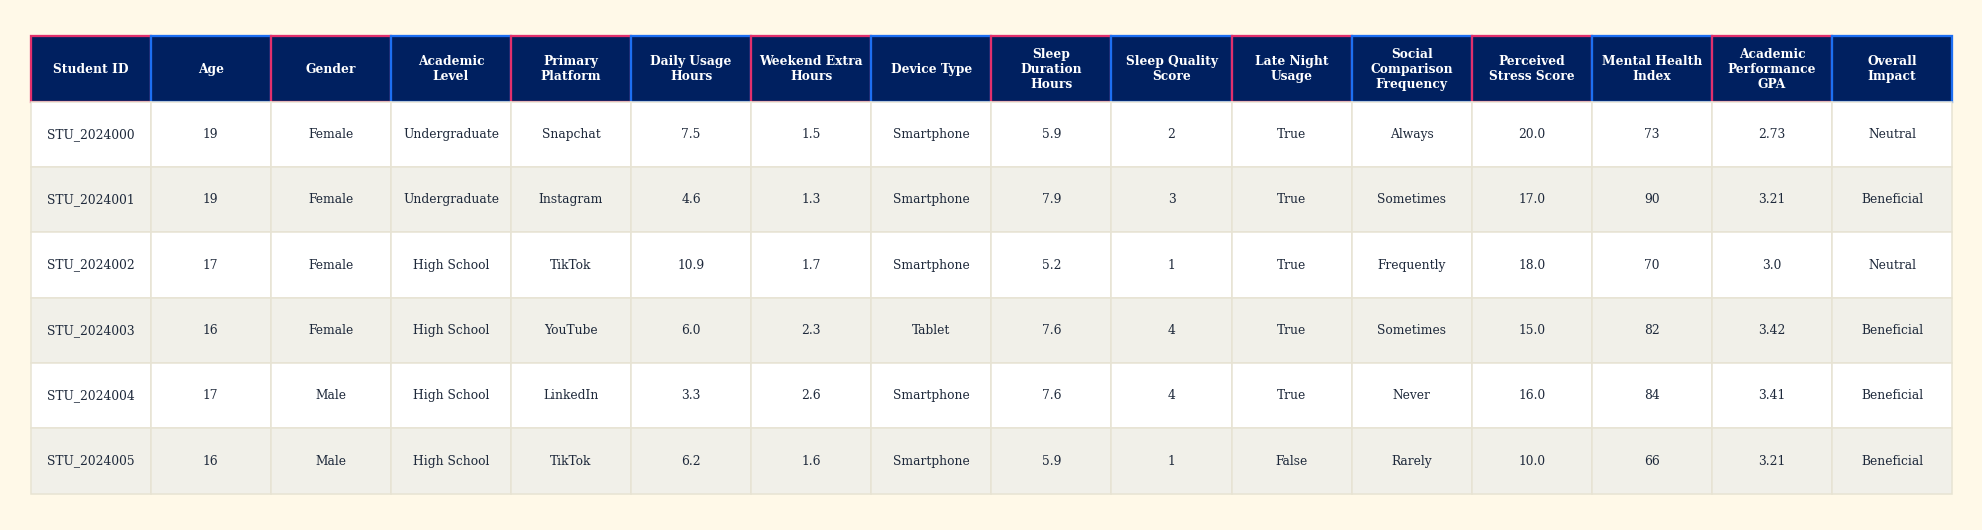

In [4]:

# DATASET TABLE — PowerPoint style

import matplotlib.pyplot as plt
import textwrap

# Original dataset
df_preview = df.copy()

if "cluster" in df_preview.columns:
    df_preview = df_preview.drop(columns=["cluster"])

# All 16 columns, first 6 records
sample = df_preview.head(6).copy()

sample.columns = [
    "\n".join(textwrap.wrap(str(c).replace("_", " "), 13))
    for c in sample.columns
]

# Same palette as the charts
BG = "#FFF9E8"
NAVY = "#002060"
BLUE = "#1D6FF2"
PINK = "#E1306C"
GRID = "#E7E3D3"
TEXT = "#1E293B"

fig, ax = plt.subplots(figsize=(23, 6))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
ax.axis("off")

# Table
table = ax.table(
    cellText=sample.astype(str).values,
    colLabels=sample.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    bbox=[0.01, 0.05, 0.98, 0.90]
)

table.auto_set_font_size(False)
table.set_fontsize(8)

for (row, col), cell in table.get_celld().items():

    cell.set_edgecolor(GRID)
    cell.set_linewidth(1)

    if row == 0:
        cell.set_facecolor(NAVY)
        cell.set_text_props(
            color="white",
            weight="bold",
            fontfamily="serif",
            fontsize=8
        )
    else:
        cell.set_facecolor(
            "#FFFFFF" if row % 2 else "#F1F0E9"
        )

        cell.set_text_props(
            color=TEXT,
            fontfamily="serif",
            fontsize=8
        )

# Pink and blue accents on the header
for col in range(len(sample.columns)):
    table[(0, col)].set_edgecolor(
        PINK if col % 2 == 0 else BLUE
    )
    table[(0, col)].set_linewidth(1.5)

# Export in vector format for PowerPoint
plt.savefig(
    "dataset_table.svg",
    format="svg",
    bbox_inches="tight",
    facecolor=BG
)

plt.show()



#Analysis of the dataset

This section performs an initial exploration of the dataset. It allows us to understand how the data is organized, identify the different variables and examine their main statistical characteristics before proceeding with the analysis.

In [5]:
print(df.shape)
df.info()
display(df.head())
display(df.describe())

(4500, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   object 
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   object 
 3   Academic_Level               4500 non-null   object 
 4   Primary_Platform             4500 non-null   object 
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   object 
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   object 
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


**Drop null**

This section prepares the dataset before clustering by cleaning it and removing unnecessary information.

In [6]:
df = df.drop_duplicates()
print(df.isna().sum())
df = df.dropna()   # oppure imputa, se i mancanti sono tanti

print(len(df))

Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64
4369


In [7]:
df['Social_Comparison_Frequency'].unique()

array(['Always', 'Sometimes', 'Frequently', 'Never', 'Rarely'],
      dtype=object)

In [8]:
df["Late_Night_Num"] = df["Late_Night_Usage"].astype(int)
mappa_confronto = {
    "Never": 0,
    "Rarely": 1,
    "Sometimes": 2,
    "Frequently": 3,
    "Always": 4
}
df["Social_Comparison_Num"] = df["Social_Comparison_Frequency"].map(mappa_confronto)

In [9]:
df["Voto_110"] = (df["Academic_Performance_GPA"] / 4 * 110).round(1)
LABELS.update({
    "Voto_110": t("Voto (su 110)", "Grade (out of 110)"),
    "Sleep_Duration_Hours": t("Durata del sonno (ore)", "Sleep duration (h)"),
    "Sleep_Quality_Score": t("Qualità del sonno", "Sleep quality"),
    "Perceived_Stress_Score": t("Stress percepito", "Perceived stress"),
    "Mental_Health_Index": t("Indice salute mentale", "Mental health index"),
    "Daily_Usage_Hours": t("Uso giornaliero (ore)", "Daily usage (h)"),
})

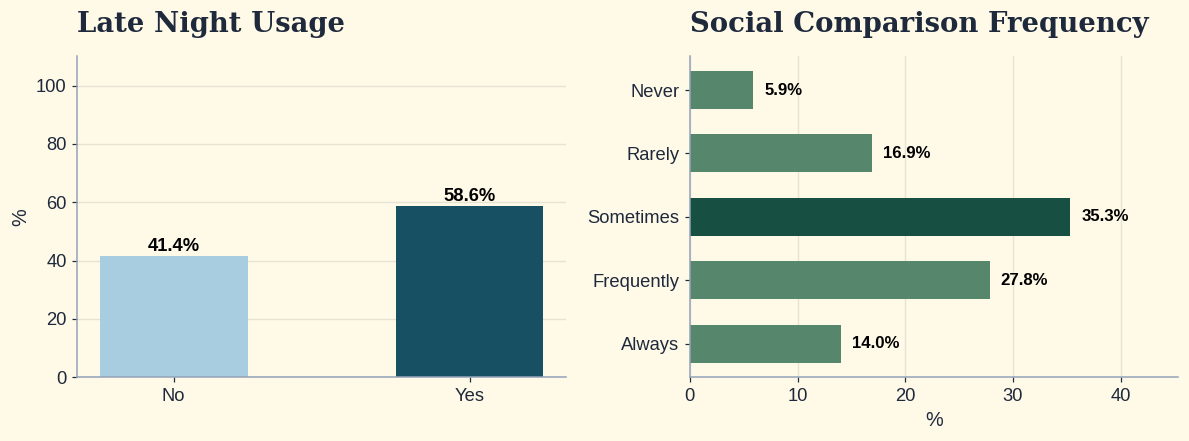

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ln = df["Late_Night_Usage"].value_counts(normalize=True) * 100
axes[0].bar(["No", "Yes"], [ln.get(False, 0), ln.get(True, 0)], color=['#A8CDE0', '#174F63'], width=0.5)
for i, v in enumerate([ln.get(False, 0), ln.get(True, 0)]):
    axes[0].text(i, v + 2, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=12)
axes[0].set_ylim(0, 110); axes[0].set_ylabel("%"); axes[0].grid(axis="x", visible=False)
titolo(axes[0], t("Uso notturno (Late Night)", "Late Night Usage"))

ordine_sc = ["Never", "Rarely", "Sometimes", "Frequently", "Always"]
sc = df["Social_Comparison_Frequency"].value_counts(normalize=True).reindex(ordine_sc).dropna() * 100

colore_barre = ['#174F43' if val == sc.max() else '#56866B' for val in sc.values]

axes[1].barh(sc.index, sc.values, color=colore_barre, height=0.6)
axes[1].invert_yaxis(); axes[1].set_xlim(0, max(sc.values) + 10); axes[1].set_xlabel("%"); axes[1].grid(axis="y", visible=False)
for i, v in enumerate(sc.values):
    axes[1].text(v + 1, i, f"{v:.1f}%", va="center", fontweight="bold", fontsize=11)
titolo(axes[1], t("Frequenza di confronto sociale", "Social Comparison Frequency"))

plt.tight_layout()
os.makedirs("grafici_ppt", exist_ok=True)
plt.savefig("grafici_ppt/eda_abitudini.png", dpi=300, bbox_inches="tight")
plt.show()

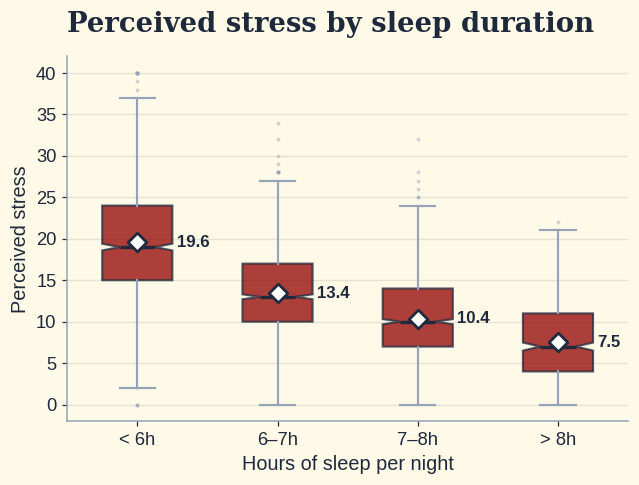

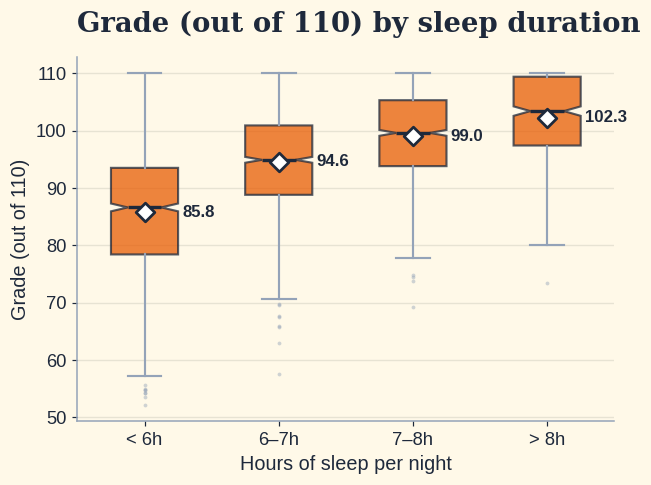

In [11]:
# Crea fasce di ore di sonno facili da leggere in presentazione
df["Fascia_Sonno"] = pd.cut(
    df["Sleep_Duration_Hours"],
    bins=[0, 6, 7, 8, 24],
    labels=["< 6h", "6–7h", "7–8h", "> 8h"]
)

def fig_fasce_sonno(y, nome_file, colore=BLUE):
    fasce = ["< 6h", "6–7h", "7–8h", "> 8h"]
    dati = [df.loc[df["Fascia_Sonno"] == f, y].dropna().values for f in fasce]

    fig, ax = plt.subplots(figsize=(6, 4.6))
    bp = ax.boxplot(
        dati, notch=True, patch_artist=True, widths=0.5,
        medianprops=dict(color=INK, lw=2.2),
        whiskerprops=dict(color=SLATE, lw=1.4),
        capprops=dict(color=SLATE, lw=1.4),
        flierprops=dict(marker="o", markersize=2.5, markerfacecolor=SLATE, markeredgecolor="none", alpha=0.45)
    )
    for patch in bp["boxes"]:
        patch.set(facecolor=colore, alpha=0.75, edgecolor=INK, linewidth=1.4)

    medie = [d.mean() for d in dati]
    pos = range(1, len(fasce) + 1)
    ax.scatter(pos, medie, marker="D", s=75, color="white", edgecolor=INK, linewidth=1.8, zorder=5)
    for p, m in zip(pos, medie):
        ax.text(p + 0.28, m, f"{m:.1f}", va="center", fontsize=11, fontweight="bold", color=INK)

    ax.set_xticks(pos)
    ax.set_xticklabels([f"{f}" for f, d in zip(fasce, dati)])
    ax.set_xlabel(t("Ore di sonno per notte", "Hours of sleep per night"))
    ax.set_ylabel(LABELS.get(y, y))
    ax.grid(axis="x", visible=False)
    titolo(ax, t(f"{LABELS.get(y, y)} per fascia di sonno", f"{LABELS.get(y, y)} by sleep duration"))

    plt.tight_layout()
    #plt.savefig(f"grafici_ppt/{nome_file}.png", dpi=300, bbox_inches="tight")
    plt.show()

fig_fasce_sonno("Perceived_Stress_Score", "fasce_sonno_stress", colore='#920100')
fig_fasce_sonno("Voto_110", "fasce_sonno_voto", colore='#e85d04')

# K-MEANS

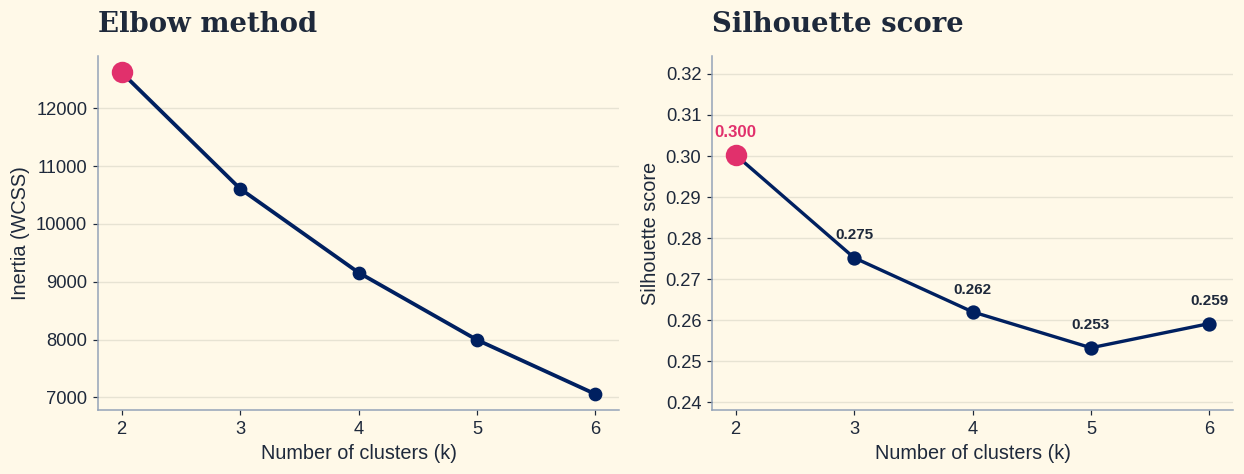

In [12]:
import os
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

os.makedirs("grafici_ppt", exist_ok=True)

# 1. Preparazione feature e scaling
df["Late_Night_Num"] = df["Late_Night_Usage"].astype(int)
df["Social_Comparison_Num"] = df["Social_Comparison_Frequency"].map(
    {"Never": 0, "Rarely": 1, "Sometimes": 2, "Frequently": 3, "Always": 4}
)
LABELS["Social_Comparison_Num"] = t("Confronto sociale", "Social comparison")

features = ["Daily_Usage_Hours", "Weekend_Extra_Hours", "Late_Night_Num", "Social_Comparison_Num"]
OUTCOMES = [
    "Sleep_Duration_Hours",
    "Sleep_Quality_Score",
    "Perceived_Stress_Score",
    "Mental_Health_Index",
    "Voto_110"  # sostituisci con "Voto_110" se preferisci il voto in 110
]
W_NIGHT = 1
X_scaled = StandardScaler().fit_transform(df[features])
X_scaled[:, features.index("Late_Night_Num")] *= W_NIGHT

# 2. Calcolo Elbow e Silhouette per K da 2 a 6
ks = list(range(2, 7))
inerzie = []
silhouettes = []

for k in ks:
    km_temp = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab_k = km_temp.fit_predict(X_scaled)
    inerzie.append(km_temp.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lab_k))

# 3. Clustering finale (K = 2)
K = 2
km = KMeans(n_clusters=K, n_init=10, random_state=42)
df["cluster"] = km.fit_predict(X_scaled)

ordine = df.groupby("cluster")["Daily_Usage_Hours"].mean().sort_values().index
df["cluster"] = df["cluster"].map({old: new for new, old in enumerate(ordine)})

def make_names(k):
    if k == 2:
        return {0: t("Moderati", "Moderate"), 1: t("Intensivi", "Intensive")}
    if k == 3:
        return {0: t("Moderati", "Moderate"), 1: t("Intermedi", "Intermediate"), 2: t("Intensivi", "Intensive")}
    return {i: f"Gruppo {i}" for i in range(k)}

def set_k(k):
    global CLUSTER_NAMES, cl
    CLUSTER_NAMES = make_names(k)
    cl = sorted(df["cluster"].unique())

set_k(K)

# 4. Grafici Elbow + Silhouette (con K=2 evidenziato in PINK)
def plot_silhouette(ax):
    ax.plot(ks, silhouettes, lw=2.2, color=NAVY, zorder=1)
    ax.scatter(ks[1:], silhouettes[1:], s=70, color=NAVY, zorder=2)
    ax.scatter([ks[0]], [silhouettes[0]], s=150, color=PINK, linewidth=1.8, zorder=3)

    offset_y = (max(silhouettes) - min(silhouettes)) * 0.08
    for i, (k, s) in enumerate(zip(ks, silhouettes)):
        ax.text(
            k, s + offset_y, f"{s:.3f}",
            ha="center", va="bottom",
            fontsize=11 if i == 0 else 10,
            fontweight="bold",
            color=PINK if i == 0 else INK
        )
    ax.set_xticks(ks)
    ax.set_ylim(min(silhouettes) * 0.94, max(silhouettes) * 1.08)
    ax.set_xlabel(t("Numero di cluster (k)", "Number of clusters (k)"))
    ax.set_ylabel(t("Silhouette score", "Silhouette score"))
    ax.grid(axis="x", visible=False)
    titolo(ax, t("Indice di Silhouette", "Silhouette score"))

# Grafico doppio affiancato
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))

axes[0].plot(ks, inerzie, marker="o", markersize=8, lw=2.5, color=NAVY)
axes[0].scatter([ks[0]], [inerzie[0]], s=150, color=PINK, linewidth=1.8, zorder=3)
axes[0].set_xticks(ks)
axes[0].set_xlabel(t("Numero di cluster (k)", "Number of clusters (k)"))
axes[0].set_ylabel(t("Inerzia (WCSS)", "Inertia (WCSS)"))
axes[0].grid(axis="x", visible=False)
titolo(axes[0], t("Metodo del gomito (Elbow)", "Elbow method"))

plot_silhouette(axes[1])

plt.tight_layout()
plt.savefig("grafici_ppt/scelta_k_elbow_silhouette.png", dpi=300, bbox_inches="tight")
plt.show()

# Salvataggio singolo della sola Silhouette
fig, ax = plt.subplots(figsize=(5.8, 4.5))
plot_silhouette(ax)
plt.tight_layout()
plt.savefig("grafici_ppt/silhouette.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# **PCA and Cluster visualisation**

After applying PCA, we represent each student in a two-dimensional space using two principal components: PC1 and PC2.

The scatter plot shows the two clusters identified by the K-Means algorithm:
- Cluster 0 – Moderate (blue): represents students with more moderate social media usage patterns. The points are mainly concentrated on the left side of the plot.
- Cluster 1 – Intensive (pink): represents students with more intensive social media usage patterns. The points are more widely distributed, mainly on the right side.
Each dot represents one student, while each colour indicates the cluster to which that student belongs.

The diamonds represent the centres of the clusters in the two-dimensional PCA space. They show the average position of the students belonging to each cluster.

The plot shows that the two groups are distinguishable, although some points overlap. This means that the clusters are not completely separated.



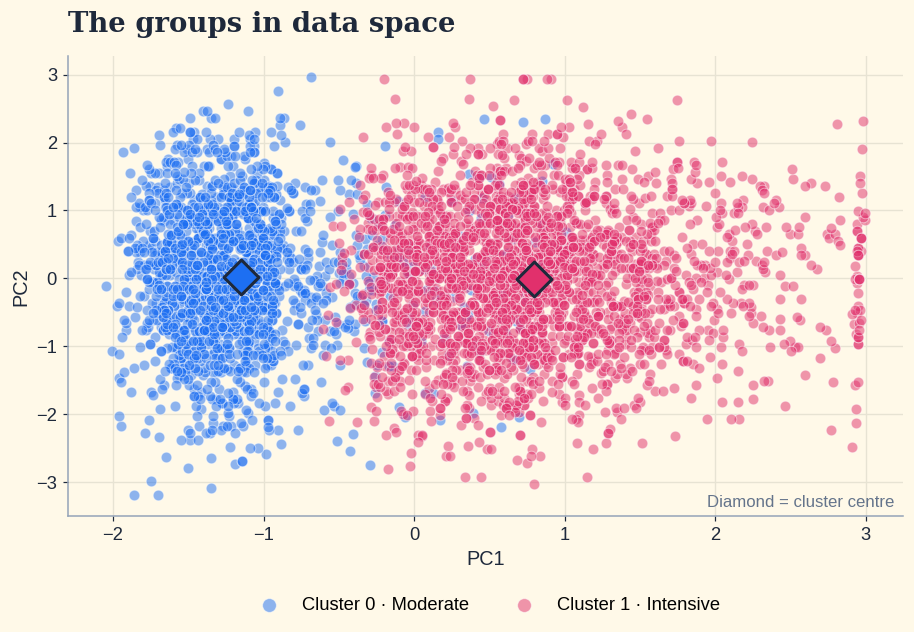

In [13]:
from sklearn.decomposition import PCA

def fig_pca():
    Xs = StandardScaler().fit_transform(df[features])
    co = PCA(2).fit_transform(Xs)
    cl_ = sorted(df["cluster"].unique())
    fig, ax = plt.subplots(figsize=(8.5, 6))
    for c in cl_:
        m = (df["cluster"] == c).values
        ax.scatter(co[m, 0], co[m, 1], s=48, color=CLUSTER_COLORS[c], alpha=0.50,
                   edgecolor="white", linewidth=0.6, label=f"{cname(c, True)}")
        ax.scatter(*co[m].mean(0), s=260, color=CLUSTER_COLORS[c], edgecolor=INK,
                   linewidth=2, marker="D", zorder=5)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=len(cl_), markerscale=1.3)
    titolo(ax, t("I gruppi nello spazio dei dati", "The groups in data space"))
    ax.text(0.99, 0.02, t("Rombo = centro del cluster", "Diamond = cluster centre"),
            transform=ax.transAxes, ha="right", color=MUTED, fontsize=11)
    fig.tight_layout(); plt.show()

fig_pca()

# CLUSTER ANALYSIS

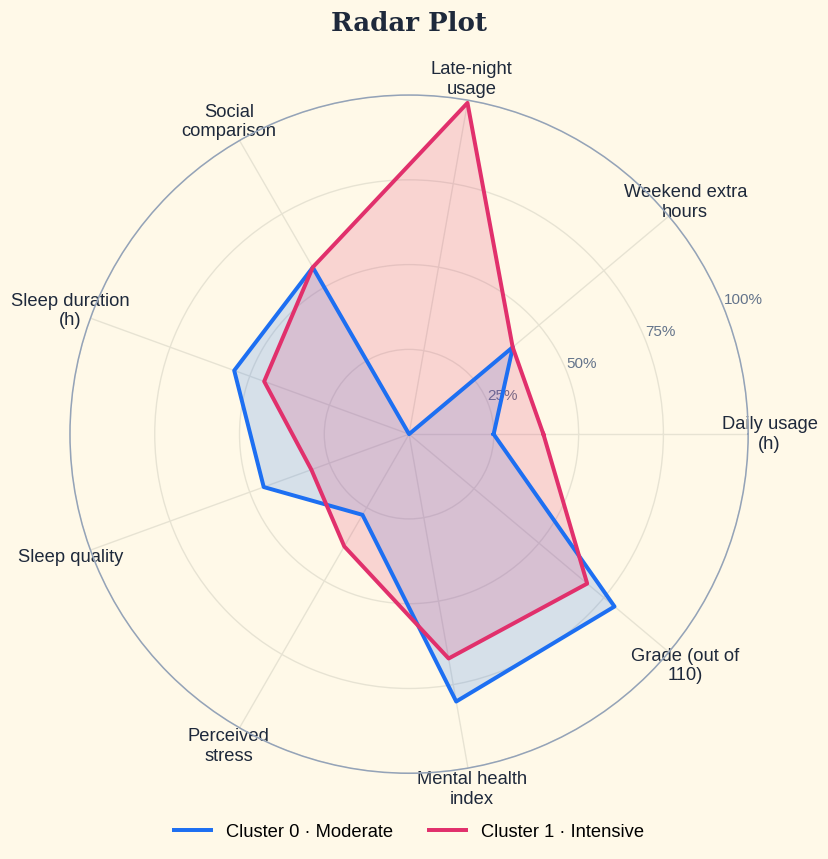

In [14]:
def fig_radar(vars_ = None):
    vars_ = vars_ or (features + OUTCOMES)
    cl_ = sorted(df["cluster"].unique())
    d = df[vars_ + ["cluster"]].copy()
    mn, mx = d[vars_].min(), d[vars_].max()
    d[vars_] = (d[vars_] - mn) / (mx - mn)
    means = d.groupby("cluster")[vars_].mean()

    ang = np.linspace(0, 2 * np.pi, len(vars_), endpoint=False).tolist()
    ang += ang[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    for c in cl_:
        v = means.loc[c].tolist(); v += v[:1]
        ax.plot(ang, v, color=CLUSTER_COLORS[c], lw=2.6, label=cname(c, True))
        ax.fill(ang, v, color=CLUSTER_COLORS[c], alpha=0.18)
    ax.set_xticks(ang[:-1])
    ax.set_xticklabels([textwrap.fill(LABELS.get(v, v.replace("_", " ")), 14) for v in vars_],
                       fontsize=12, color=INK)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["25%", "50%", "75%", "100%"], fontsize=10, color=MUTED)
    ax.set_rlabel_position(22)   # sposta le etichette in un punto libero tra gli assi
    ax.grid(color=GRID)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=len(cl_))
    ax.set_title(t("Profilo dei cluster (0 = minimo, 1 = massimo)", "Radar Plot"),
                 fontfamily=SERIF, fontsize=17, fontweight="bold", color=INK, pad=42)
    plt.tight_layout(); plt.show()

fig_radar()

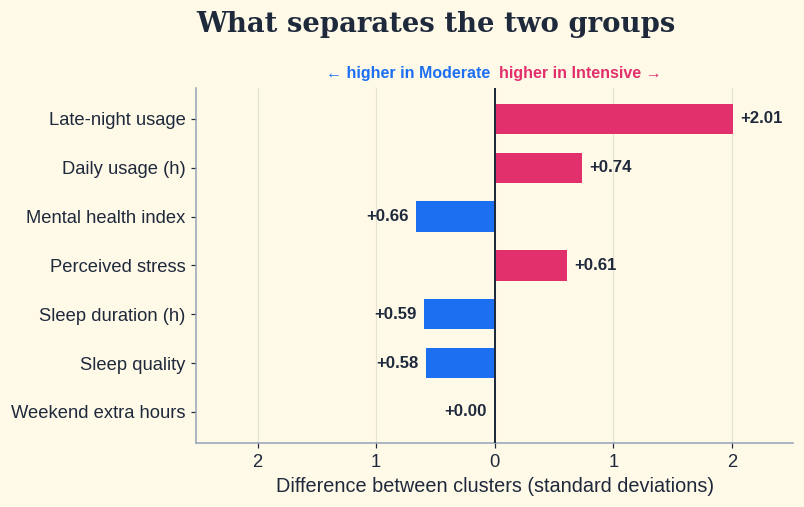

In [15]:
from sklearn.preprocessing import StandardScaler

vars_diff = [
    "Mental_Health_Index",
    "Sleep_Quality_Score",
    "Daily_Usage_Hours",
    "Sleep_Duration_Hours",
    "Perceived_Stress_Score",
    "Late_Night_Num",
    "Weekend_Extra_Hours",
]

# Standardizzazione sull'intero dataset
df_z = pd.DataFrame(
    StandardScaler().fit_transform(df[vars_diff]),
    columns=vars_diff,
    index=df.index
)

# Differenza tra medie standardizzate: Cluster 1 (Intensive) - Cluster 0 (Moderate)
medie_c0 = df_z[df["cluster"] == 0].mean()
medie_c1 = df_z[df["cluster"] == 1].mean()
diff = (medie_c1 - medie_c0)

# Ordina per valore assoluto crescente (così la barra più grande va in cima al barh)
diff = diff.reindex(diff.abs().sort_values(ascending=True).index)

fig, ax = plt.subplots(figsize=(7.5, 4.8))

colors = [PINK if v > 0 else BLUE for v in diff.values]
etichette = [LABELS.get(c, c) for c in diff.index]

bars = ax.barh(etichette, diff.values, color=colors, height=0.62, zorder=3)
ax.axvline(0, color=INK, lw=1.3, zorder=4)

# Etichette numeriche (+valore assoluto) alle estremità delle barre
max_val = diff.abs().max()
for bar, v in zip(bars, diff.values):
    offset = max_val * 0.03 if v >= 0 else -max_val * 0.03
    ha = "left" if v >= 0 else "right"
    ax.text(
        v + offset, bar.get_y() + bar.get_height() / 2,
        f"+{abs(v):.2f}",
        va="center", ha=ha, fontweight="bold", fontsize=11, color=INK
    )

# Sottotitolo direzionale (← higher in Moderate | higher in Intensive →)
lim = max_val * 1.25
ax.set_xlim(-lim, lim)
ax.set_xticks([-2, -1, 0, 1, 2])
ax.set_xticklabels(["2", "1", "0", "1", "2"])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID, linestyle="-", linewidth=0.8, zorder=0)

ax.set_xlabel(t("Differenza tra cluster (deviazioni standard)", "Difference between clusters (standard deviations)"))
titolo(ax, t("Cosa separa i due gruppi", "What separates the two groups\n"))
ax.title.set_y(1.11)
# Sottotitolo colorato sopra le barre
ax.text(-0.04, 1.02, t("← più alto in Moderate", "← higher in Moderate"),
        transform=ax.get_xaxis_transform(), ha="right", va="bottom",
        color=BLUE, fontweight="bold", fontsize=10.5)
ax.text(0.04, 1.02, t("più alto in Intensive →", "higher in Intensive →"),
        transform=ax.get_xaxis_transform(), ha="left", va="bottom",
        color=PINK, fontweight="bold", fontsize=10.5)

plt.tight_layout()
plt.savefig("grafici_ppt/what_separates_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
def fig_num(col, ax=None):
    cl_ = sorted(df["cluster"].unique())
    data_df = df[["cluster", col]].dropna()
    grouped = [data_df.loc[data_df["cluster"] == c, col].values for c in cl_]

    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(2.2 * len(cl_) + 3, 5))

    bp = ax.boxplot(
        grouped,
        notch=True,
        patch_artist=True,
        widths=0.5,
        medianprops=dict(color=INK, lw=2.2),
        whiskerprops=dict(color=SLATE, lw=1.5),
        capprops=dict(color=SLATE, lw=1.5),
        flierprops=dict(marker="o", markersize=2.5, markerfacecolor=SLATE, markeredgecolor="none", alpha=0.5)
    )
    for patch, c in zip(bp["boxes"], cl_):
        patch.set(facecolor=CLUSTER_COLORS[c], alpha=0.75, edgecolor=INK, linewidth=1.5)

    means = [vals.mean() for vals in grouped]
    positions = range(1, len(cl_) + 1)
    ax.scatter(positions, means, marker="D", s=80, color="white", edgecolor=INK, linewidth=1.8, zorder=5)
    for pos, m in zip(positions, means):
        ax.text(pos + 0.28, m, f"{m:.1f}", va="center", fontsize=11, fontweight="bold", color=INK)

    ax.set_xticks(positions)
    ax.set_xticklabels([f"{cname(c, True).replace(' · ', chr(10))}\n(n={len(vals)})" for c, vals in zip(cl_, grouped)], fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(LABELS.get(col, col))
    ax.grid(axis="x", visible=False)
    ax.text(0.99, 0.02, t("Rombo = media", "Diamond = mean"), transform=ax.transAxes, ha="right", color=MUTED, fontsize=10)
    titolo(ax, LABELS.get(col, col))

    if own:
        plt.tight_layout(); plt.show()

In [17]:
def fig_cat(col, order=None, colors=None, ax=None):
    cl = sorted(df["cluster"].unique())
    tab = pd.crosstab(df["cluster"], df[col], normalize="index").reindex(cl) * 100
    if order:
        tab = tab[order]
    cols = colors or {cat: EXTRA[i % len(EXTRA)] for i, cat in enumerate(tab.columns)}

    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(10, 1.1 * len(cl) + 2.4))

    left = np.zeros(len(tab))
    for cat in tab.columns:
        ax.barh(range(len(tab)), tab[cat].values, left=left, color=cols[cat],
                edgecolor=BG, height=0.62, label=cat)
        for j, v in enumerate(tab[cat].values):
            if v >= 6:
                ax.text(left[j] + v / 2, j, f"{v:.0f}%", ha="center", va="center",
                        color="white", fontweight="bold", fontsize=12)
        left += tab[cat].values

    ax.set_yticks(range(len(tab)))
    ax.set_yticklabels([cname(c, True) for c in tab.index])
    ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.grid(False); ax.set_xlabel("%")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=min(len(tab.columns), 4))
    titolo(ax, t(f"{_lab(col)} per cluster", f"{_lab(col)} by cluster"))
    if own:
        plt.tight_layout(); plt.show()


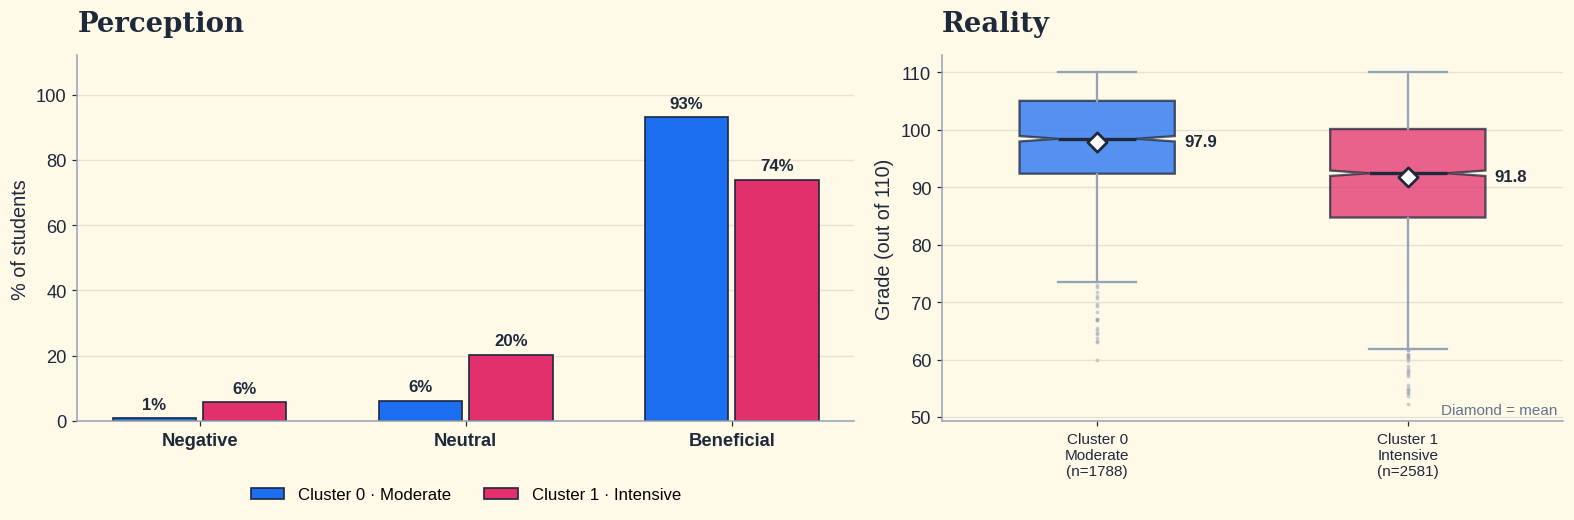

In [18]:
def fig_cat_grouped(col="Overall_Impact", order=("Negative", "Neutral", "Beneficial"), ax=None):
    cl_ = sorted(df["cluster"].unique())
    tab = pd.crosstab(df["cluster"], df[col], normalize="index").reindex(cl_) * 100
    tab = tab[[o for o in order if o in tab.columns]]

    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7.5, 4.8))

    x = np.arange(len(tab.columns))
    width = 0.34

    for i, c in enumerate(cl_):
        vals = tab.loc[c].values
        offset = (i - 0.5) * width
        bars = ax.bar(x + offset, vals, width=width * 0.92, color=CLUSTER_COLORS[c],
                      edgecolor=INK, linewidth=1.1, label=cname(c, True))
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.0f}%",
                    ha="center", va="bottom", fontsize=11, fontweight="bold", color=INK)

    ax.set_xticks(x)
    ax.set_xticklabels(tab.columns, fontsize=12, fontweight="bold", color=INK)
    ax.set_ylim(0, 112)
    ax.set_ylabel(t("% di studenti", "% of students"))
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=len(cl_), frameon=False, fontsize=11)

    if own:
        titolo(ax, t("Percezione dell'impatto", "Perceived impact"))
        plt.tight_layout()
        plt.show()

def fig_percezione_grouped():
    fig, axes = plt.subplots(1, 2, figsize=(14.5, 5), gridspec_kw={"width_ratios": [1.25, 1]})
    fig_cat_grouped("Overall_Impact", ax=axes[0])
    fig_num("Voto_110", ax=axes[1])
    axes[0].set_title(t("Percezione", "Perception"), loc="left", fontfamily=SERIF, fontsize=18, fontweight="bold", color=INK, pad=16)
    axes[1].set_title(t("Realtà", "Reality"), loc="left", fontfamily=SERIF, fontsize=18, fontweight="bold", color=INK, pad=16)
    plt.tight_layout()
    plt.savefig("grafici_ppt/percezione_vs_realta.png", dpi=300, bbox_inches="tight")
    plt.show()

fig_percezione_grouped()

In [19]:
from scipy.stats import spearmanr

def fig_num(col, ax=None):
    cl_ = sorted(df["cluster"].unique())
    data_df = df[["cluster", col]].dropna()
    grouped = [data_df.loc[data_df["cluster"] == c, col].values for c in cl_]

    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(2.2 * len(cl_) + 3, 5))

    bp = ax.boxplot(
        grouped,
        notch=True,
        patch_artist=True,
        widths=0.5,
        medianprops=dict(color=INK, lw=2.2),
        whiskerprops=dict(color=SLATE, lw=1.5),
        capprops=dict(color=SLATE, lw=1.5),
        flierprops=dict(marker="o", markersize=2.5, markerfacecolor=SLATE, markeredgecolor="none", alpha=0.5)
    )
    for patch, c in zip(bp["boxes"], cl_):
        patch.set(facecolor=CLUSTER_COLORS[c], alpha=0.75, edgecolor=INK, linewidth=1.5)

    means = [vals.mean() for vals in grouped]
    positions = range(1, len(cl_) + 1)
    ax.scatter(positions, means, marker="D", s=80, color="white", edgecolor=INK, linewidth=1.8, zorder=5)
    for pos, m in zip(positions, means):
        ax.text(pos + 0.28, m, f"{m:.1f}", va="center", fontsize=11, fontweight="bold", color=INK)

    ax.set_xticks(positions)
    ax.set_xticklabels([f"{cname(c, True).replace(' · ', chr(10))}" for c, vals in zip(cl_, grouped)], fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(LABELS.get(col, col))
    ax.grid(axis="x", visible=False)
    titolo(ax, LABELS.get(col, col))

    if own:
        ax.text(0.99, 0.02, t("Rombo = media", "Diamond = mean"), transform=ax.transAxes, ha="right", color=MUTED, fontsize=10)
        plt.tight_layout()
        plt.show()

def fig_dose(x="Daily_Usage_Hours", ys=("Sleep_Duration_Hours", "Perceived_Stress_Score", "Mental_Health_Index", "Voto_110"), per_cluster_reg=False):
    cl_ = sorted(df["cluster"].unique())
    fig, axes = plt.subplots(1, len(ys), figsize=(4.3 * len(ys), 4.6))
    axes = np.atleast_1d(axes)

    for ax, y in zip(axes, ys):
        for c in cl_:
            s = df[df.cluster == c]
            ax.scatter(s[x], s[y], s=16, color=CLUSTER_COLORS[c], alpha=0.28, edgecolor="none")
            if per_cluster_reg:
                sns.regplot(data=s, x=x, y=y, scatter=False, ci=95, color=CLUSTER_COLORS[c],
                            line_kws=dict(lw=2.2), ax=ax)
        if not per_cluster_reg:
            sns.regplot(data=df, x=x, y=y, scatter=False, ci=95, color=INK, line_kws=dict(lw=2.2), ax=ax)

        v = df[[x, y]].dropna()
        r = spearmanr(v[x], v[y])[0]
        ax.text(0.04, 0.05, f"ρ = {r:+.2f}", transform=ax.transAxes, fontsize=12, fontweight="bold",
                color=INK, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID))
        ax.set_title(LABELS.get(y, y), fontsize=13, fontweight="bold", color=INK, pad=10)
        ax.set_xlabel(LABELS.get(x, x))
        ax.set_ylabel("")

    handles = [plt.Line2D([], [], marker="o", ls="", color=CLUSTER_COLORS[c], label=cname(c, True), ms=9) for c in cl_]
    fig.legend(handles=handles, loc="lower center", ncol=len(cl_), frameon=False, bbox_to_anchor=(0.5, -0.03))
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

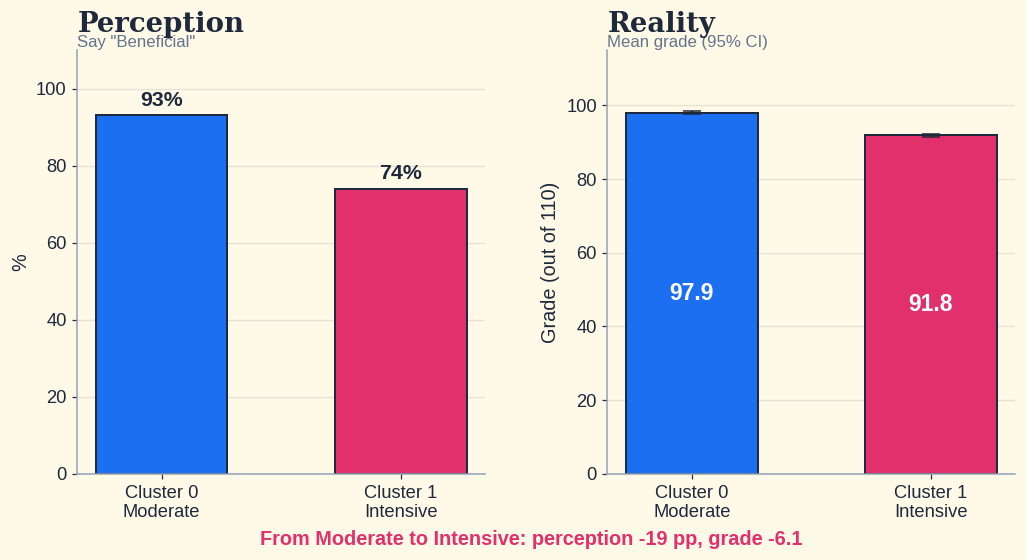

In [20]:
def fig_gap(perc_label="Beneficial", voto="Voto_110"):
    cl_ = sorted(df["cluster"].unique())
    cols = [CLUSTER_COLORS[c] for c in cl_]
    names = [cname(c, True).replace(" · ", "\n") for c in cl_]

    # Percezione: % di "Beneficial" per cluster
    pct = [(df.loc[df.cluster == c, "Overall_Impact"] == perc_label).mean() * 100 for c in cl_]
    # Realtà: voto medio e IC 95%
    d = df[["cluster", voto]].dropna()
    mean = [d.loc[d.cluster == c, voto].mean() for c in cl_]
    ci = [1.96 * d.loc[d.cluster == c, voto].sem() for c in cl_]

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"wspace": 0.3})

    ax = axes[0]
    b = ax.bar(names, pct, color=cols, width=0.55, edgecolor=INK, linewidth=1.3)
    ax.bar_label(b, labels=[f"{v:.0f}%" for v in pct], padding=4, fontsize=14, fontweight="bold", color=INK)
    ax.set_ylim(0, 110); ax.set_ylabel("%"); ax.grid(axis="x", visible=False)
    ax.set_title(t("Percezione", "Perception"), loc="left", fontfamily=SERIF, fontsize=18, fontweight="bold", color=INK, pad=12)
    ax.text(0, 1.0, t(f'Dicono "{perc_label}"', f'Say "{perc_label}"'), transform=ax.transAxes,
            va="bottom", color=MUTED, fontsize=11)

    ax = axes[1]
    b = ax.bar(names, mean, yerr=ci, capsize=6, color=cols, width=0.55, edgecolor=INK, linewidth=1.3,
               error_kw=dict(ecolor=INK, lw=1.6))
    for rect, m in zip(b, mean):
        ax.text(rect.get_x() + rect.get_width() / 2, m / 2, f"{m:.1f}", ha="center", va="center",
                color="white", fontsize=15, fontweight="bold")
    ax.set_ylim(0, 115); ax.set_ylabel(LABELS.get(voto, voto)); ax.grid(axis="x", visible=False)
    ax.set_title(t("Realtà", "Reality"), loc="left", fontfamily=SERIF, fontsize=18, fontweight="bold", color=INK, pad=12)
    ax.text(0, 1.0, t("Voto medio (IC 95%)", "Mean grade (95% CI)"), transform=ax.transAxes,
            va="bottom", color=MUTED, fontsize=11)

    # Differenza tra primo e ultimo cluster, scritta sul grafico
    delta_p, delta_v = pct[-1] - pct[0], mean[-1] - mean[0]
    fig.text(0.5, -0.02, t(f"Da {cname(cl_[0])} a {cname(cl_[-1])}: percezione {delta_p:+.0f} punti %, voto {delta_v:+.1f}",
                           f"From {cname(cl_[0])} to {cname(cl_[-1])}: perception {delta_p:+.0f} pp, grade {delta_v:+.1f}"),
             ha="center", fontsize=13, fontweight="bold", color=PINK)
    plt.show()

fig_gap()

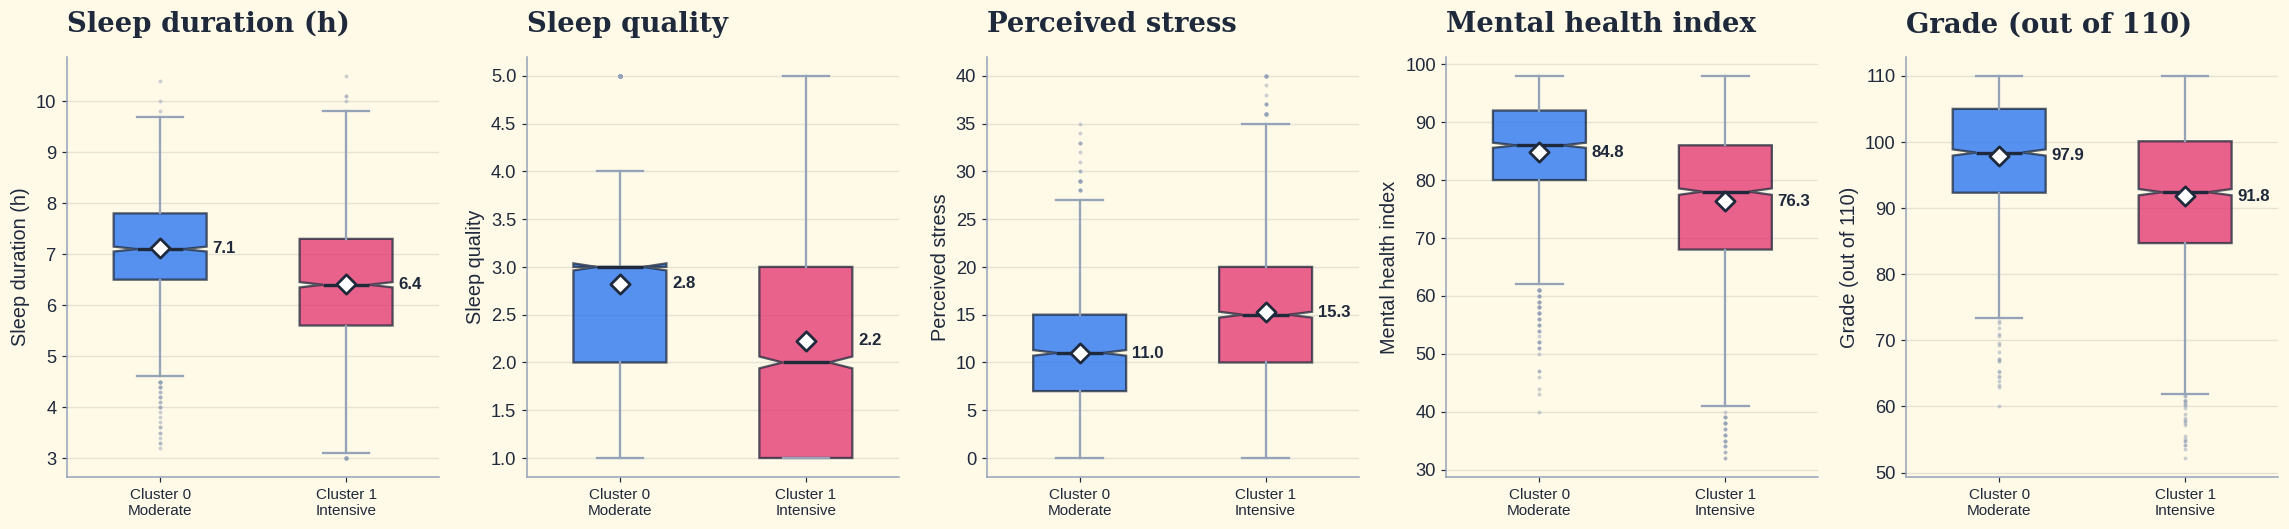

In [21]:
OUTCOMES_PLOT = [
    "Sleep_Duration_Hours",
    "Sleep_Quality_Score",
    "Perceived_Stress_Score",
    "Mental_Health_Index",
    "Voto_110"
]

fig, axes = plt.subplots(1, len(OUTCOMES_PLOT), figsize=(21, 5))
for ax, col in zip(axes, OUTCOMES_PLOT):
    fig_num(col, ax=ax)

plt.tight_layout()
plt.show()

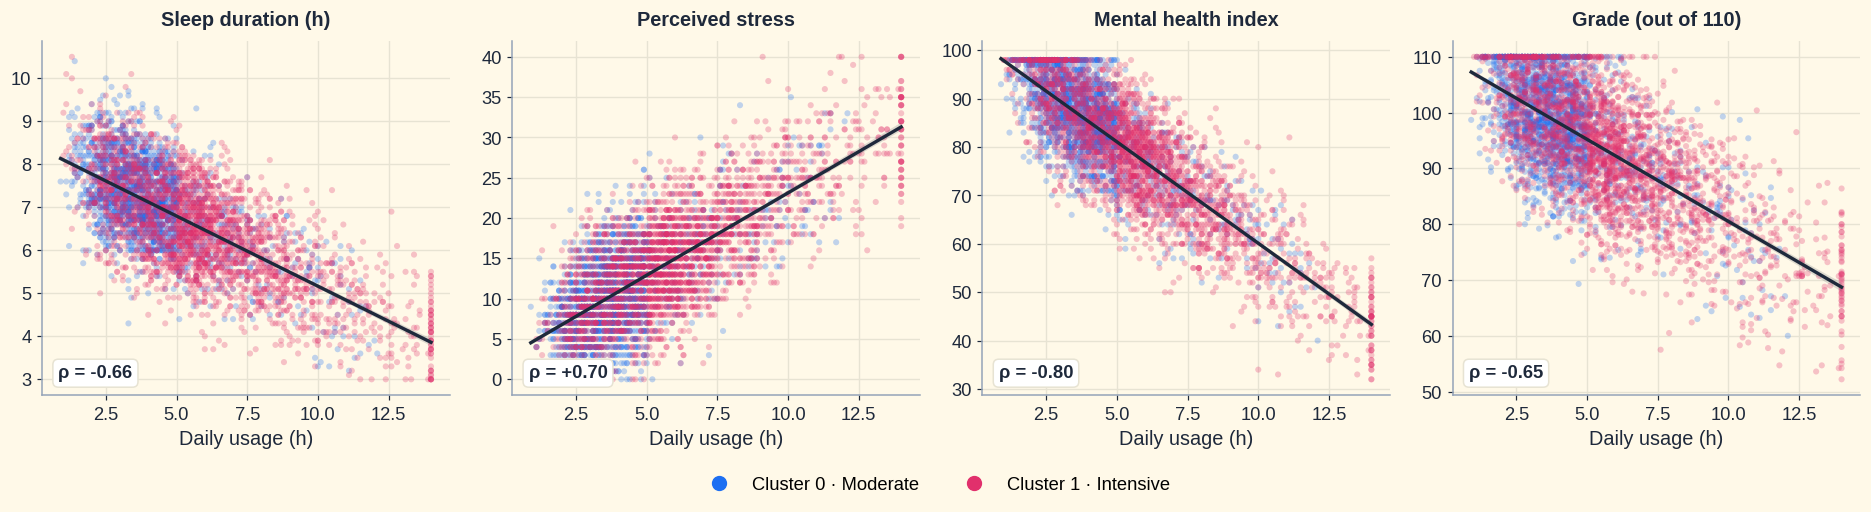

In [22]:
fig_dose(
    x="Daily_Usage_Hours",
    ys=("Sleep_Duration_Hours", "Perceived_Stress_Score", "Mental_Health_Index", "Voto_110"),
    per_cluster_reg=False
)

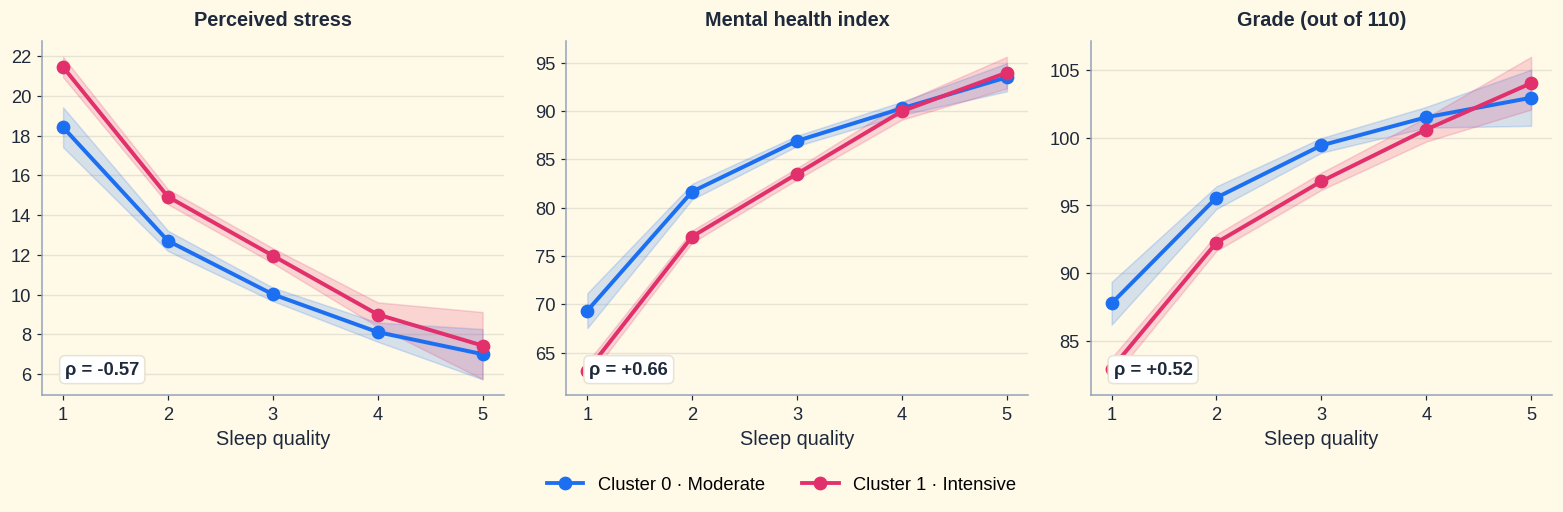

In [23]:
def fig_sonno_trend(ys=("Perceived_Stress_Score", "Mental_Health_Index", "Voto_110")):
    cl_ = sorted(df["cluster"].unique())
    livelli = sorted(df["Sleep_Quality_Score"].dropna().unique())

    fig, axes = plt.subplots(1, len(ys), figsize=(4.8 * len(ys), 4.6))
    axes = np.atleast_1d(axes)

    for ax, y in zip(axes, ys):
        for c in cl_:
            sub = df[df["cluster"] == c].dropna(subset=["Sleep_Quality_Score", y])
            stats = sub.groupby("Sleep_Quality_Score")[y].agg(["mean", "count", "std"]).reindex(livelli)
            # Mostra solo livelli con almeno 5 osservazioni per evitare punte rumorose
            stats = stats[stats["count"] >= 5]
            ci95 = 1.96 * (stats["std"] / np.sqrt(stats["count"]))

            ax.plot(stats.index, stats["mean"], marker="o", markersize=8, lw=2.6,
                    color=CLUSTER_COLORS[c], label=cname(c, True))
            ax.fill_between(stats.index, stats["mean"] - ci95, stats["mean"] + ci95,
                            color=CLUSTER_COLORS[c], alpha=0.18)

        v = df[["Sleep_Quality_Score", y]].dropna()
        r = spearmanr(v["Sleep_Quality_Score"], v[y])[0]
        ax.text(0.05, 0.06, f"ρ = {r:+.2f}", transform=ax.transAxes, fontsize=12, fontweight="bold",
                color=INK, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=GRID))

        ax.set_xticks(livelli)
        ax.set_title(LABELS.get(y, y), fontsize=13, fontweight="bold", color=INK, pad=10)
        ax.set_xlabel(LABELS.get("Sleep_Quality_Score", "Sleep quality (1–5)"))
        ax.set_ylabel("")
        ax.grid(axis="x", visible=False)

    handles = [plt.Line2D([], [], marker="o", lw=2.5, color=CLUSTER_COLORS[c], label=cname(c, True), ms=8) for c in cl_]
    fig.legend(handles=handles, loc="lower center", ncol=len(cl_), frameon=False, bbox_to_anchor=(0.5, -0.03))

    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.savefig("grafici_ppt/sonno_trend_multiplo.png", dpi=300, bbox_inches="tight")
    plt.show()

fig_sonno_trend()

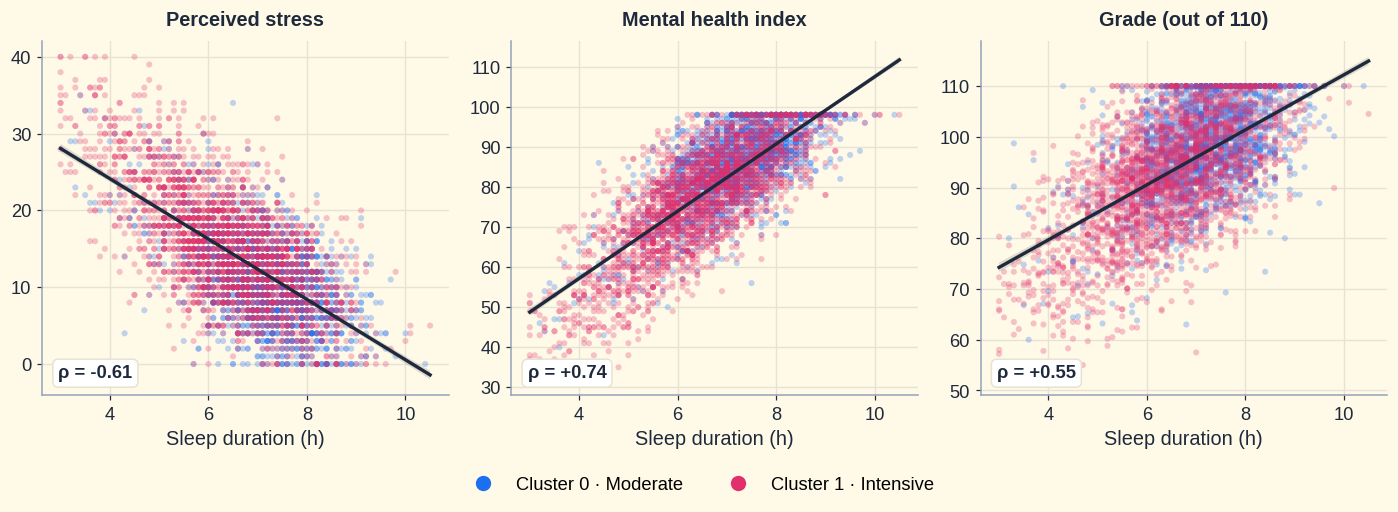

In [24]:
fig_dose(
    x="Sleep_Duration_Hours",
    ys=("Perceived_Stress_Score", "Mental_Health_Index", "Voto_110"),
    per_cluster_reg=False
)